 Création du Jupyter pour la solution sur étagère.


In [123]:
# Import library
from dotenv import load_dotenv
from pathlib import Path
import os
import logging
from tqdm.notebook import tqdm
import pickle

from azure.ai.textanalytics import TextAnalyticsClient
from azure.core.credentials import AzureKeyCredential

import pandas as pd
import numpy as np
from datetime import datetime, timedelta
import time
import matplotlib.pyplot as plt
from sklearn import metrics


In [2]:
# Define the constants
# For requests : https://docs.microsoft.com/fr-fr/azure/cognitive-services/text-analytics/concepts/data-limits?tabs=version-3
MAX_DOCUMENTS_PER_REQUEST = 10
MAX_SIZE_DOCUMENT = 125_000
# If F0 -> 100 & 300. If S -> 1_000 & 1_000
# MAX_REQUEST_PER_SECOND_F0 = 100
MAX_REQUEST_PER_SECOND  = 100
MAX_REQUEST_PER_MINUTE  = 300

# For data
FILE_DF_TEST = 'df_test_'
FILE_DICT_RESULTS = "dict_results_API"
FILE_DF_RESULTS = "df_results_API"
SIZE_TEST = 1_000

In [3]:
# Authenticate
# Read the keys
env_path = Path('./data')/'.env'
load_dotenv(dotenv_path= env_path)

# Function do authenticate the client
def authenticate_client():
    ta_credential = AzureKeyCredential(os.getenv("KEY1"))
    text_analytics_client = TextAnalyticsClient(
                                        endpoint= os.getenv("ENDPOINT"),
                                        credential= ta_credential)
    return text_analytics_client

# Authenticate the client
client = authenticate_client()

In [4]:
# Load the samples for test
df_test = pd.read_pickle(Path('./data/')/f"{FILE_DF_TEST}{SIZE_TEST}.pkl")

In [5]:
# Loop on the tweets to call the API
# Start by defining the variables
results = {
            'index' : [],
            'response' : [],
            'id' : [],
            'sentiment' : [],
            'warnings' : [],
            'statistics' : [],
            'score_negative' : [],
            'score_neutral' : [],
            'score_positive' : [],
            'sentence' : [],
            'errors' : []
}

index_tweets = list(df_test.index)
current_loop = 0
now = datetime.now()
stack_of_time_per_second = MAX_REQUEST_PER_SECOND * [now]
stack_of_time_per_minute = MAX_REQUEST_PER_MINUTE * [
                    now - timedelta(seconds= 60)
]

progress_bar = tqdm(
                    total= len(df_test),
                    desc= "API",
                    leave= False
)
while (current_loop * MAX_DOCUMENTS_PER_REQUEST) < len(df_test):
    # Wait the 1 second between requests
    while (
            (
                datetime.now() 
                - stack_of_time_per_second[
                                        current_loop % MAX_REQUEST_PER_SECOND
                    ]
            ).seconds < 1
    ):
        must_wait = (
                        1 
                        - (
                            datetime.now() 
                            - stack_of_time_per_second[
                                        current_loop % MAX_REQUEST_PER_SECOND
                                ]
                        ).seconds
        )
        logging.debug(msg= f"Attends la seconde {must_wait}s")
        if must_wait > 0:
            time.sleep(must_wait)

    # Wait the minute between requests
    while (
            (
                datetime.now() 
                - stack_of_time_per_minute[
                                        current_loop % MAX_REQUEST_PER_MINUTE
                    ]
            ).seconds < 60
    ):
        must_wait = (
                        60 
                        - (
                            datetime.now() 
                            - stack_of_time_per_minute[
                                        current_loop % MAX_REQUEST_PER_MINUTE
                                ]
                        ).seconds
        )
        logging.debug(msg= f"Attends la minute : {must_wait}s")
        if must_wait > 0:
            time.sleep(must_wait)

    # We create the documents
    starting_index = current_loop * MAX_DOCUMENTS_PER_REQUEST
    ending_index = (current_loop + 1) * MAX_DOCUMENTS_PER_REQUEST
    mask = index_tweets[starting_index:ending_index]
    documents = df_test.loc[mask, "tweet"].values

    # Make the request
    response = client.analyze_sentiment(list(documents))
    response = response

    for i in range(len(response)):
        results['index'].append(mask[i])
        current_response = response[i]
        results['response'].append(current_response)
        results['id'].append(current_response['id'])
        results['sentiment'].append(current_response['sentiment'])
        results['warnings'].append(current_response['warnings'])
        results['statistics'].append(current_response['statistics'])
        results['score_negative'].append(
                            current_response['confidence_scores']['negative']
        )
        results['score_neutral'].append(
                            current_response['confidence_scores']['neutral']
        )
        results['score_positive'].append(
                            current_response['confidence_scores']['positive']
        )
        tmp_sentences = current_response['sentences']
        value = {
                    'text' : [],
                    'sentiment' : [],
                    'confidence_score_negative' : [],
                    'confidence_score_neutral' : [],
                    'confidence_score_positive' : [],
                    'offset' : [],
                    'mined_opinions' : []
        }
        for j in range(len(tmp_sentences)):
            value['text'].append(tmp_sentences[j]['text'])
            value['sentiment'].append(tmp_sentences[j]['sentiment'])
            value['confidence_score_negative'].append(
                            tmp_sentences[j]['confidence_scores']['negative']
            )
            value['confidence_score_neutral'].append(
                            tmp_sentences[j]['confidence_scores']['neutral']
            )
            value['confidence_score_positive'].append(
                            tmp_sentences[j]['confidence_scores']['positive']
            )
            value['offset'].append(tmp_sentences[j]['offset'])
            value['mined_opinions'].append(tmp_sentences[j]['mined_opinions'])
        results['sentence'].append(value)
        results['errors'].append(current_response['is_error'])
    

    # Update the data
    stack_of_time_per_second[current_loop % MAX_REQUEST_PER_SECOND] = \
                                                                datetime.now()
    stack_of_time_per_minute[current_loop % MAX_REQUEST_PER_MINUTE] = \
                                                                datetime.now()
    
    # Finish the loop.
    current_loop += 1
    progress_bar.update(MAX_DOCUMENTS_PER_REQUEST)
progress_bar.close()

API:   0%|          | 0/1000 [00:00<?, ?it/s]

In [6]:
# Save the results
with open(Path('./data')/f"{FILE_DICT_RESULTS}.pkl", 'wb') as handle:
    pickle.dump(
                results, 
                handle, 
                protocol= pickle.HIGHEST_PROTOCOL,
    )

In [7]:
# Create dataframe
df_results = pd.DataFrame(
                    data= {
                            key : value for key, value in results.items()
                            if key in [
                                        'index', 
#                                        'response',
                                        'id',
                                        'sentiment',
                                        'score_negative',
                                        'score_neutral',
                                        'score_positive',
                                        'sentence',
                                        'warnings',
                                        'statistics',
                                        'errors'
                                    ]
                    }
)
df_results.to_pickle(Path('./data')/f"{FILE_DF_RESULTS}.pkl")

Affichage des résultats

In [10]:
# Load the data
df_results = pd.read_pickle(Path('./data')/f"{FILE_DF_RESULTS}.pkl")
df_results.sample(10)

,index,id,sentiment,warnings,statistics,score_negative,score_neutral,score_positive,sentence,errors
602,1066337,2,neutral,[],None,0.03,0.71,0.26,{'text': ['@fuseboxradio ty how u been mama?...,False
902,1061516,2,mixed,[],None,0.52,0.24,0.24,"{'text': ['allergies suck.', 'getting off at 4...",False
229,622298,9,negative,[],None,0.52,0.00,0.48,"{'text': ['@suki I envy you'], 'sentiment': ['...",False
214,366409,4,positive,[],None,0.09,0.01,0.90,"{'text': ['going hiking with the kids today.',...",False
853,1506437,3,positive,[],None,0.11,0.25,0.64,"{'text': ['@ralfvdz Haha, it won't be Breda W...",False
921,1042525,1,positive,[],None,0.03,0.47,0.50,{'text': ['@SandiHockeyMom : a lot of hot ladi...,False
96,469872,6,neutral,[],None,0.07,0.91,0.02,{'text': ['@amitgupta at least ur MC is trippi...,False
869,1568766,9,positive,[],None,0.00,0.00,1.00,"{'text': ['@sethsimonds I require your help, k...",False
112,798575,2,neutral,[],None,0.19,0.78,0.03,{'text': ['@ericboehs Man I can't even remembe...,False
509,1163632,9,neutral,[],None,0.08,0.82,0.10,"{'text': ['grocery time.', 'then back to editi...",False


In [130]:
mask = df_test['score'] == 0
negative_index = df_test.loc[mask].index
mask = [x in negative_index for x in df_results['index']]
negative_results = df_results.loc[mask, 'sentiment'].value_counts()
mask = [x not in negative_index for x in df_results['index']]
positive_results = df_results.loc[mask, 'sentiment'].value_counts()

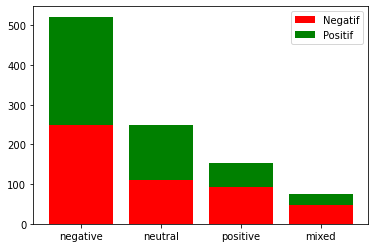

In [131]:
fig, ax = plt.subplots()
ax.bar(
        x= negative_results.index,
        height= negative_results.values,
        color= ['red'],
        label= 'Negatif'
)
ax.bar(
        x= negative_results.index,
        height= positive_results.values,
        bottom= negative_results.values,
        color= ['green'],
        label= 'Positif'
)
plt.legend()
plt.show()

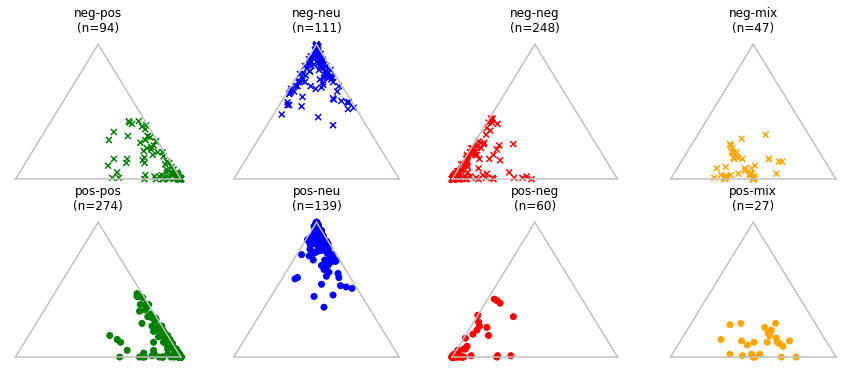

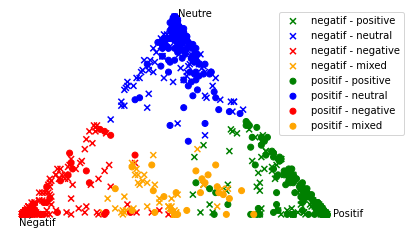

In [170]:
figs, axs = plt.subplots(
                        nrows= 2,
                        ncols= 4,
                        sharex= True,
                        sharey= True,
                        figsize= (15, 6)
)

fig, ax = plt.subplots()
code_sentiment = {
                    'negatif' : 0,
                    'positif' : 1
}
marker_style = {
                    'negatif' : 'x',
                    'positif' : 'o'                
}
c_dict = {
            'positive' : 'green', 
            'neutral'  : 'blue', 
            'negative' : 'red',
            'mixed'    : 'orange'
}

row = 0
for sentiment in ['negatif', 'positif']:
    col = 0
    for predicted_sentiment in c_dict.keys():
        mask_index = df_test.loc[
                            df_test['score'] == code_sentiment[sentiment]
        ].index
        mask = [
                x['sentiment'] == predicted_sentiment
                if x['index'] in mask_index else False
                for index, x in df_results.iterrows()
        ]
        x = [
                0 * x['score_negative']                               \
                    + np.cos(np.pi/3) * x['score_neutral']            \
                    + 1 * x['score_positive']
                for index, x in df_results.loc[mask].iterrows()
        ]
        y = [
                0 * x['score_negative']                               \
                    + np.sin(np.pi/3) * x['score_neutral']            \
                    + 0 * x['score_positive']
                for index, x in df_results.loc[mask].iterrows()
        ]

        colors = [c_dict[x] for x in df_results.loc[mask, 'sentiment']]

        axs[row, col].scatter(
                                x= x,
                                y= y,
                                c= colors,
                                marker= marker_style[sentiment],
                                label= f"{sentiment} - {predicted_sentiment}"
        )
        axs[row, col].plot(
                            [0, np.cos(np.pi/3)], [0, np.sin(np.pi/3)],
                            [np.cos(np.pi/3), 1], [np.sin(np.pi/3), 0],
                            [0, 1], [0, 0],
                            c= 'silver'
        )
        axs[row, col].set_axis_off()
        axs[row, col].set_title(
                f"{sentiment[:3]}-{predicted_sentiment[:3]}\n(n={len(x)})")
        col += 1
        ax.scatter(
                    x= x,
                    y= y,
                    c= colors,
                    marker= marker_style[sentiment],
                    label= f"{sentiment} - {predicted_sentiment}"
        )
    row += 1
        
plt.legend(
            loc= 'upper right',
            bbox_to_anchor= [1.2, 1]
)
plt.text(x= -.01, y= -0.05, s= "Négatif")
plt.text(x= 1.02, y= -0.01, s= "Positif")
plt.text(x= np.cos(np.pi/3) + 0.01, y= np.sin(np.pi/3), s= "Neutre")
plt.grid(False)
plt.axis('off')
plt.show()

In [129]:
df_test.head()

,score,tweet
336882,0,how about i just do yall a favour nd put a fuc...
617477,0,@FayeeToooley I feel realllllly sick tooo x
348706,0,"@timskirven yeah, tons of spam, so annoying. ..."
269816,0,I dont want to let her go. Sad morning! @Tinac...
535070,0,Woke up at 5am so unfair


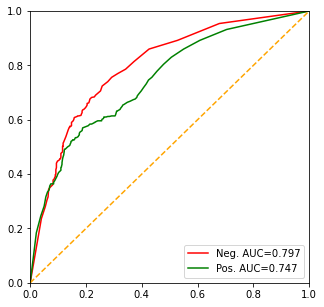

In [165]:
fpr, tpr, thresholds = metrics.roc_curve(
                                            df_test['score'],
                                            df_results['score_negative'],
                                            pos_label= 0
)
auc = metrics.roc_auc_score(
                            [1 if x == 0 else 0 for x in df_test['score']],
                            df_results['score_negative']
)
fig, ax = plt.subplots(figsize=(5,5))
ax.plot(
        fpr,
        tpr,
        c= 'red',
        label= f"Neg. AUC={auc:.3f}"
)

fpr, tpr, thresholds = metrics.roc_curve(
                                            df_test['score'],
                                            df_results['score_positive'],
                                            pos_label= 1
)
auc = metrics.roc_auc_score(
                            df_test['score'],
                            df_results['score_positive']
)
ax.plot(
        fpr,
        tpr,
        c= 'green',
        label= f"Pos. AUC={auc:.3f}"
)
ax.plot(
        [0, 1],
        [0, 1],
        linestyle= 'dashed',
        c= 'orange'
)

plt.legend()
plt.xlim(left= 0, right= 1)
plt.ylim(bottom= 0, top= 1)
plt.show()

In [172]:
(0.797 + 0.747)/2

0.772